Best Route: [2, 3, 0, 1, 2]
Best Distance: 14.0


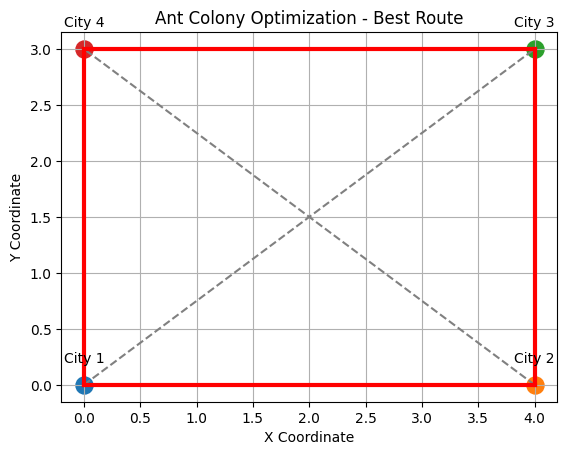

In [1]:
import random
import math
import matplotlib.pyplot as plt

# City coordinates
cities = [(0, 0), (4, 0), (4, 3), (0, 3)]
n = len(cities)

# Calculate distance between cities
distance = [[0] * n for _ in range(n)]

for i in range(n):
    for j in range(n):
        x1, y1 = cities[i]
        x2, y2 = cities[j]
        distance[i][j] = math.sqrt((x2-x1)**2 + (y2-y1)**2)

# Initialize pheromone
pheromone = [[1] * n for _ in range(n)]

ants = 10
iterations = 50
best_route = None
best_distance = float('inf')

# ACO algorithm
for iteration in range(iterations):

    for ant in range(ants):

        route = [random.randint(0, n-1)]

        while len(route) < n:
            current = route[-1]
            choices = [i for i in range(n) if i not in route]

            probabilities = [
                pheromone[current][i] / distance[current][i]
                for i in choices
            ]

            next_city = random.choices(
                choices, weights=probabilities
            )[0]

            route.append(next_city)

        route.append(route[0])

        total = sum(
            distance[route[i]][route[i+1]]
            for i in range(n)
        )

        if total < best_distance:
            best_distance = total
            best_route = route

        # Update pheromone
        for i in range(n):
            a = route[i]
            b = route[i+1]
            pheromone[a][b] += 1 / total
            pheromone[b][a] += 1 / total

    # Evaporation
    for i in range(n):
        for j in range(n):
            pheromone[i][j] *= 0.9

# Display result
print("Best Route:", best_route)
print("Best Distance:", best_distance)

# Draw graph
for i in range(n):
    for j in range(i+1, n):
        x = [cities[i][0], cities[j][0]]
        y = [cities[i][1], cities[j][1]]
        plt.plot(x, y, 'gray', linestyle='--')

# Highlight best route
for i in range(n):
    a = best_route[i]
    b = best_route[i+1]

    x = [cities[a][0], cities[b][0]]
    y = [cities[a][1], cities[b][1]]

    plt.plot(x, y, 'r-', linewidth=3)

# Draw cities
for i, (x, y) in enumerate(cities):
    plt.scatter(x, y, s=150)
    plt.text(x, y+0.2, "City " + str(i+1), ha='center')

plt.title("Ant Colony Optimization - Best Route")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid()
plt.show()